In [ ]:
import mujoco
import numpy as np
import matplotlib.pyplot as plt

print("MuJoCo version:", mujoco.__version__)

MuJoCo version: 3.1.4


In [3]:
{
 "cells": [
  {
   "cell_type": "markdown",
   "metadata": {},
   "source": [
    "# MuJoCo Basics — A Hands-On Notebook\n",
    "\n",
    "This notebook covers the core MuJoCo workflow:\n",
    "1. **Setup** — verify your install\n",
    "2. **Model & Data** — the two central objects\n",
    "3. **Stepping** — advancing the simulation\n",
    "4. **Visualization** — rendering frames\n",
    "5. **Control** — driving a pendulum with an actuator\n",
    "6. **Loading** — using bundled models\n",
    "\n",
    "Run each cell in order. Every example is self-contained."
   ]
  },
  {
   "cell_type": "code",
   "execution_count": null,
   "metadata": {},
   "outputs": [],
   "source": [
    "# 1. Setup — verify everything is working\n",
    "import mujoco\n",
    "import numpy as np\n",
    "import matplotlib.pyplot as plt\n",
    "\n",
    "print(\"MuJoCo:\", mujoco.__version__)\n",
    "print(\"NumPy:\", np.__version__)\n",
    "print(\"Architecture:\", __import__('platform').machine())\n",
    "\n",
    "%matplotlib inline"
   ]
  },
  {
   "cell_type": "markdown",
   "metadata": {},
   "source": [
    "## 2. Model & Data\n",
    "\n",
    "MuJoCo separates **static** description from **dynamic** state:\n",
    "\n",
    "- **`MjModel`** — the blueprint: masses, geometry, joints, timestep. Built once from XML.\n",
    "- **`MjData`** — the scratchpad: current positions, velocities, forces. Updated every step.\n",
    "\n",
    "Models are defined in **MJCF** (MuJoCo's XML format). Here is the simplest possible scene: a floor and a falling ball."
   ]
  },
  {
   "cell_type": "code",
   "execution_count": null,
   "metadata": {},
   "outputs": [],
   "source": [
    "# Define a minimal model\n",
    "XML = \"\"\"\n",
    "<mujoco>\n",
    "  <option gravity=\"0 0 -9.81\"/>\n",
    "  <worldbody>\n",
    "    <light pos=\"0 0 3\" diffuse=\"0.8 0.8 0.8\"/>\n",
    "    <geom name=\"floor\" type=\"plane\" size=\"5 5 0.1\" rgba=\"0.4 0.4 0.4 1\"/>\n",
    "    <body name=\"ball\" pos=\"0 0 2\">\n",
    "      <joint name=\"ball_free\" type=\"free\"/>\n",
    "      <geom name=\"ball_geom\" type=\"sphere\" size=\"0.2\" rgba=\"1 0.2 0.2 1\"/>\n",
    "    </body>\n",
    "  </worldbody>\n",
    "</mujoco>\n",
    "\"\"\"\n",
    "\n",
    "# Build model and data\n",
    "model = mujoco.MjModel.from_xml_string(XML)\n",
    "data = mujoco.MjData(model)\n",
    "\n",
    "print(f\"Bodies:  {model.nbody}\")\n",
    "print(f\"Geoms:   {model.ngeom}\")\n",
    "print(f\"Joints:  {model.njnt}\")\n",
    "print(f\"qpos:    {data.qpos}   # [x, y, z, qw, qx, qy, qz]\")\n",
    "print(f\"Timestep: {model.opt.timestep} s\")"
   ]
  },
  {
   "cell_type": "markdown",
   "metadata": {},
   "source": [
    "## 3. Stepping the Simulation\n",
    "\n",
    "The core loop is: **reset → step → read state**.\n",
    "\n",
    "`mj_step(model, data)` advances physics by one timestep. Record the ball's height over time."
   ]
  },
  {
   "cell_type": "code",
   "execution_count": null,
   "metadata": {},
   "outputs": [],
   "source": [
    "# Reset to initial state\n",
    "mujoco.mj_resetData(model, data)\n",
    "\n",
    "heights = []\n",
    "times = []\n",
    "\n",
    "for _ in range(400):          # 400 * 0.002s = 0.8s\n",
    "    mujoco.mj_step(model, data)\n",
    "    heights.append(data.qpos[2])\n",
    "    times.append(data.time)\n",
    "\n",
    "plt.figure(figsize=(10, 4))\n",
    "plt.plot(times, heights, linewidth=2)\n",
    "plt.axhline(0.2, color='k', ls='--', alpha=0.5, label='floor contact (r=0.2)')\n",
    "plt.xlabel(\"Time (s)\")\n",
    "plt.ylabel(\"Ball height (m)\")\n",
    "plt.title(\"Bouncing ball — data.qpos[2] over time\")\n",
    "plt.legend()\n",
    "plt.grid(alpha=0.3)\n",
    "plt.show()"
   ]
  },
  {
   "cell_type": "markdown",
   "metadata": {},
   "source": [
    "## 4. Visualization — Rendering Frames\n",
    "\n",
    "`mujoco.Renderer` produces RGB images offscreen. This is how you create videos, visual observations for RL, or debug renders.\n",
    "\n",
    "**Note:** On macOS this typically works out of the box. On headless Linux you'd set `MUJOCO_GL=egl` or `osmesa`."
   ]
  },
  {
   "cell_type": "code",
   "execution_count": null,
   "metadata": {},
   "outputs": [],
   "source": [
    "mujoco.mj_resetData(model, data)\n",
    "\n",
    "renderer = mujoco.Renderer(model, height=240, width=320)\n",
    "frames = []\n",
    "\n",
    "for i in range(300):\n",
    "    mujoco.mj_step(model, data)\n",
    "    if i % 30 == 0:                       # capture every 30 steps\n",
    "        renderer.update_scene(data)\n",
    "        frames.append(renderer.render())\n",
    "\n",
    "renderer.close()\n",
    "\n",
    "# Display as a strip\n",
    "fig, axes = plt.subplots(1, len(frames), figsize=(3*len(frames), 3))\n",
    "for ax, f in zip(axes, frames):\n",
    "    ax.imshow(f)\n",
    "    ax.axis(\"off\")\n",
    "plt.suptitle(\"Rendered frames of the falling ball\")\n",
    "plt.tight_layout()\n",
    "plt.show()"
   ]
  },
  {
   "cell_type": "markdown",
   "metadata": {},
   "source": [
    "## 5. Control — Driving a Pendulum\n",
    "\n",
    "Now a model with an **actuator**. A hinge joint (1 DOF) plus a motor lets us apply torque.\n",
    "\n",
    "Set `data.ctrl[0]` each step to control the motor."
   ]
  },
  {
   "cell_type": "code",
   "execution_count": null,
   "metadata": {},
   "outputs": [],
   "source": [
    "PENDULUM_XML = \"\"\"\n",
    "<mujoco>\n",
    "  <option gravity=\"0 0 -9.81\"/>\n",
    "  <worldbody>\n",
    "    <light pos=\"0 0 3\"/>\n",
    "    <geom type=\"plane\" size=\"5 5 0.1\" rgba=\"0.4 0.4 0.4 1\"/>\n",
    "    <body name=\"pole\" pos=\"0 0 1\">\n",
    "      <joint name=\"hinge\" type=\"hinge\" axis=\"0 1 0\"/>\n",
    "      <geom type=\"capsule\" fromto=\"0 0 0  0 0 -0.5\" size=\"0.05\" rgba=\"0.2 0.6 1 1\"/>\n",
    "      <geom type=\"sphere\" pos=\"0 0 -0.5\" size=\"0.08\" rgba=\"1 0.8 0 1\"/>  <!-- bob -->\n",
    "    </body>\n",
    "  </worldbody>\n",
    "  <actuator>\n",
    "    <motor joint=\"hinge\" name=\"motor\" ctrlrange=\"-5 5\"/>\n",
    "  </actuator>\n",
    "</mujoco>\n",
    "\"\"\"\n",
    "\n",
    "pmodel = mujoco.MjModel.from_xml_string(PENDULUM_XML)\n",
    "pdata = mujoco.MjData(pmodel)\n",
    "\n",
    "angles = []\n",
    "ctrls = []\n",
    "\n",
    "for i in range(1000):\n",
    "    t = pdata.time\n",
    "    pdata.ctrl[0] = 3.0 * np.sin(2 * np.pi * 1.0 * t)   # 1 Hz sine torque\n",
    "    mujoco.mj_step(pmodel, pdata)\n",
    "    angles.append(pdata.qpos[0])     # hinge angle\n",
    "    ctrls.append(pdata.ctrl[0])\n",
    "\n",
    "fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 5), sharex=True)\n",
    "ax1.plot(angles, color='tab:blue'); ax1.set_ylabel(\"Angle (rad)\"); ax1.grid(alpha=0.3)\n",
    "ax2.plot(ctrls, color='tab:orange'); ax2.set_ylabel(\"Torque\"); ax2.set_xlabel(\"Step\"); ax2.grid(alpha=0.3)\n",
    "ax1.set_title(\"Pendulum driven by a sinusoidal torque\")\n",
    "plt.tight_layout()\n",
    "plt.show()"
   ]
  },
  {
   "cell_type": "markdown",
   "metadata": {},
   "source": [
    "## 6. Loading Bundled Models\n",
    "\n",
    "MuJoCo ships with classic benchmark models (humanoid, ant, cheetah, etc.). Let's find them."
   ]
  },
  {
   "cell_type": "code",
   "execution_count": null,
   "metadata": {},
   "outputs": [],
   "source": [
    "import os\n",
    "\n",
    "model_dir = os.path.join(os.path.dirname(mujoco.__file__), \"model\")\n",
    "print(\"Bundled models:\", model_dir)\n",
    "\n",
    "if os.path.isdir(model_dir):\n",
    "    for name in sorted(os.listdir(model_dir)):\n",
    "        print(\"  -\", name)\n",
    "else:\n",
    "    print(\"Not found — this build may not ship samples.\")"
   ]
  },
  {
   "cell_type": "markdown",
   "metadata": {},
   "source": [
    "### Try the humanoid\n",
    "\n",
    "It has many degrees of freedom and will collapse under gravity with no control input — a good sanity check that physics is running."
   ]
  },
  {
   "cell_type": "code",
   "execution_count": null,
   "metadata": {},
   "outputs": [],
   "source": [
    "humanoid_path = os.path.join(model_dir, \"humanoid\", \"humanoid.xml\")\n",
    "\n",
    "if os.path.exists(humanoid_path):\n",
    "    hmodel = mujoco.MjModel.from_xml_path(humanoid_path)\n",
    "    hdata = mujoco.MjData(hmodel)\n",
    "    print(f\"Humanoid loaded — nq={hmodel.nq}, nu={hmodel.nu} (DOFs, actuators)\")\n",
    "\n",
    "    renderer = mujoco.Renderer(hmodel, height=400, width=500)\n",
    "    for _ in range(200):\n",
    "        mujoco.mj_step(hmodel, hdata)\n",
    "    renderer.update_scene(hdata)\n",
    "    img = renderer.render()\n",
    "    renderer.close()\n",
    "\n",
    "    plt.figure(figsize=(6, 5))\n",
    "    plt.imshow(img)\n",
    "    plt.axis(\"off\")\n",
    "    plt.title(\"MuJoCo humanoid after 0.4s of free fall\")\n",
    "    plt.show()\n",
    "else:\n",
    "    print(\"humanoid.xml not found in this build.\")"
   ]
  },
  {
   "cell_type": "markdown",
   "metadata": {},
   "source": [
    "## Recap — The Core Pattern\n",
    "\n",
    "Every MuJoCo program follows this shape:\n",
    "\n",
    "```python\n",
    "model = mujoco.MjModel.from_xml_string(XML)   # static\n",
    "data  = mujoco.MjData(model)                  # dynamic\n",
    "\n",
    "while simulating:\n",
    "    data.ctrl[:] = ...          # set controls (if any)\n",
    "    mujoco.mj_step(model, data) # advance physics\n",
    "    obs = data.qpos, data.qvel  # read state\n",
    "```\n",
    "\n",
    "### Where to go next\n",
    "- **XML Reference**: https://mujoco.readthedocs.io/en/stable/XMLreference.html\n",
    "- **Official tutorials**: https://github.com/google-deepmind/mujoco/tree/main/python/tutorial\n",
    "- **MuJoCo Menagerie** (ready-made robots): https://github.com/google-deepmind/mujoco_menagerie\n",
    "- **Gymnasium environments** for RL: `pip install gymnasium[mujoco]`"
   ]
  }
 ],
 "metadata": {
  "kernelspec": {
   "display_name": "Python 3",
   "language": "python",
   "name": "python3"
  },
  "language_info": {
   "name": "python",
   "version": "3.12"
  }
 },
 "nbformat": 4,
 "nbformat_minor": 5
}

NameError: name 'null' is not defined

In [4]:
import mujoco
import numpy as np
import matplotlib.pyplot as plt
print("MuJoCo:", mujoco.__version__)
print("Architecture:", __import__('platform').machine())

MuJoCo: 3.1.4
Architecture: arm64


In [5]:
XML = """
<mujoco>
  <option gravity="0 0 -9.81"/>
  <worldbody>
    <light pos="0 0 3"/>
    <geom name="floor" type="plane" size="5 5 0.1" rgba="0.4 0.4 0.4 1"/>
    <body name="ball" pos="0 0 2">
      <joint name="ball_free" type="free"/>
      <geom name="ball_geom" type="sphere" size="0.2" rgba="1 0.2 0.2 1"/>
    </body>
  </worldbody>
</mujoco>
"""

model = mujoco.MjModel.from_xml_string(XML)
data = mujoco.MjData(model)
print(f"Bodies: {model.nbody}, Geoms: {model.ngeom}, Joints: {model.njnt}")
print("qpos:", data.qpos)

Bodies: 2, Geoms: 2, Joints: 1
qpos: [0. 0. 2. 1. 0. 0. 0.]


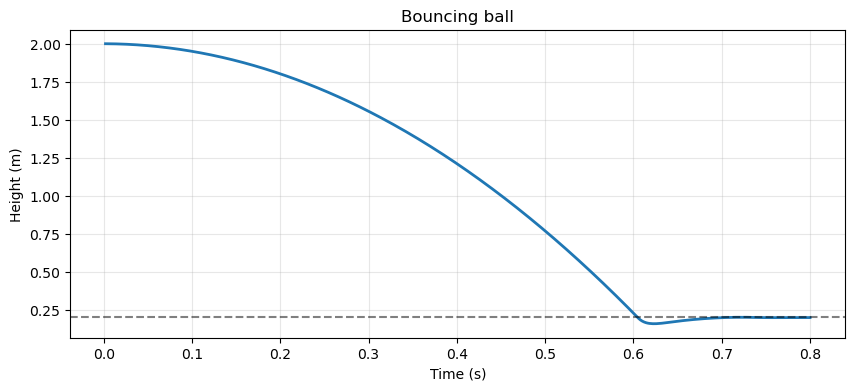

In [6]:
mujoco.mj_resetData(model, data)
heights, times = [], []
for _ in range(400):
    mujoco.mj_step(model, data)
    heights.append(data.qpos[2])
    times.append(data.time)

plt.figure(figsize=(10, 4))
plt.plot(times, heights, linewidth=2)
plt.axhline(0.2, color='k', ls='--', alpha=0.5)
plt.xlabel("Time (s)"); plt.ylabel("Height (m)")
plt.title("Bouncing ball"); plt.grid(alpha=0.3); plt.show()

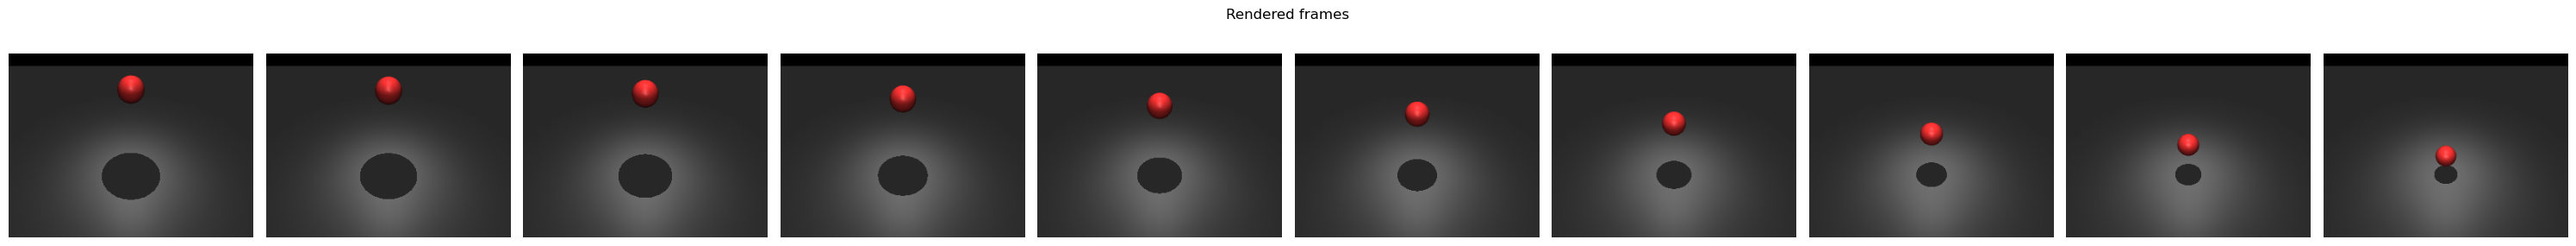

In [7]:
mujoco.mj_resetData(model, data)
renderer = mujoco.Renderer(model, height=240, width=320)
frames = []
for i in range(300):
    mujoco.mj_step(model, data)
    if i % 30 == 0:
        renderer.update_scene(data)
        frames.append(renderer.render())
renderer.close()

fig, axes = plt.subplots(1, len(frames), figsize=(3*len(frames), 3))
for ax, f in zip(axes, frames):
    ax.imshow(f); ax.axis("off")
plt.suptitle("Rendered frames"); plt.tight_layout(); plt.show()

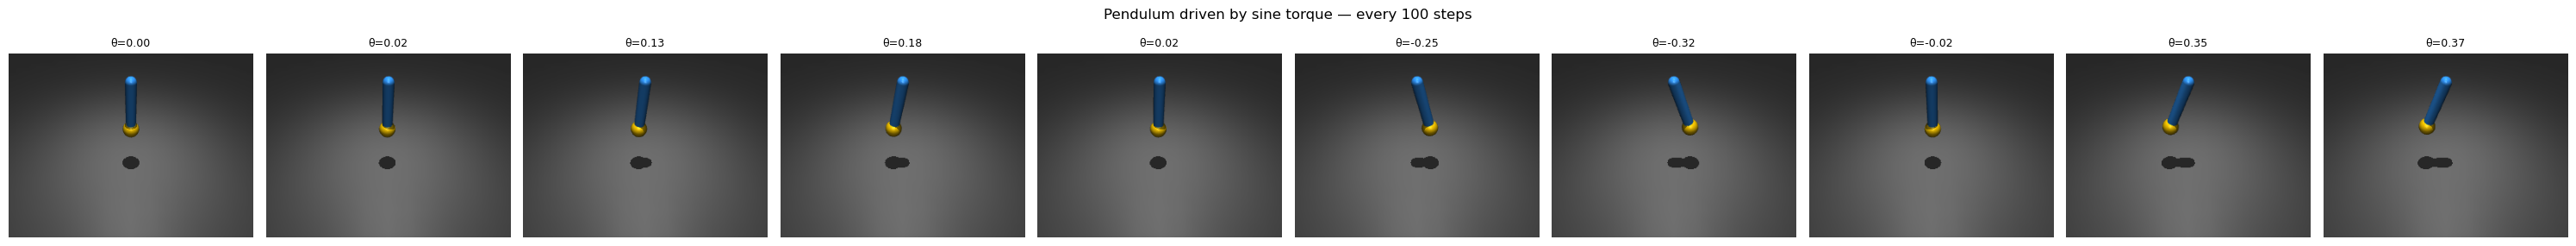

In [9]:
import mujoco
import numpy as np
import matplotlib.pyplot as plt

PENDULUM_XML = """
<mujoco>
  <option gravity="0 0 -9.81"/>
  <worldbody>
    <light pos="0 0 3"/>
    <geom type="plane" size="5 5 0.1" rgba="0.4 0.4 0.4 1"/>
    <body name="pole" pos="0 0 1">
      <joint name="hinge" type="hinge" axis="0 1 0"/>
      <geom type="capsule" fromto="0 0 0  0 0 -0.5" size="0.05" rgba="0.2 0.6 1 1"/>
      <geom type="sphere" pos="0 0 -0.5" size="0.08" rgba="1 0.8 0 1"/>
    </body>
  </worldbody>
  <actuator>
    <motor joint="hinge" name="motor" ctrlrange="-5 5"/>
  </actuator>
</mujoco>
"""

pmodel = mujoco.MjModel.from_xml_string(PENDULUM_XML)
pdata = mujoco.MjData(pmodel)

# --- Simulate and capture frames ---
renderer = mujoco.Renderer(pmodel, height=240, width=320)
frames = []
angles = []

for i in range(1000):
    # 1 Hz sine torque, amplitude 3
    pdata.ctrl[0] = 3.0 * np.sin(2 * np.pi * 1.0 * pdata.time)
    mujoco.mj_step(pmodel, pdata)

    # capture every 100 steps -> 10 frames
    if i % 100 == 0:
        renderer.update_scene(pdata)
        frames.append(renderer.render())
        angles.append(pdata.qpos[0])

renderer.close()

# --- Display as a strip ---
fig, axes = plt.subplots(1, len(frames), figsize=(3 * len(frames), 3))
for ax, f, a in zip(axes, frames, angles):
    ax.imshow(f)
    ax.axis("off")
    ax.set_title(f"θ={a:.2f}", fontsize=9)

plt.suptitle("Pendulum driven by sine torque — every 100 steps", fontsize=12)
plt.tight_layout()
plt.show()

In [12]:
import mujoco
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import animation
from IPython.display import HTML

# ---------- 1. Define the model ----------
DOUBLE_PENDULUM_XML = """
<mujoco>
  <option gravity="0 0 -9.81"/>
  <worldbody>
    <light pos="0 0 3"/>
    <geom type="plane" size="5 5 0.1" rgba="0.4 0.4 0.4 1"/>

    <body name="upper" pos="0 0 1.5">
      <joint name="shoulder" type="hinge" axis="0 1 0"/>
      <geom type="capsule" fromto="0 0 0  0 0 -0.5" size="0.04" rgba="0.2 0.6 1 1"/>

      <body name="lower" pos="0 0 -0.5">
        <joint name="elbow" type="hinge" axis="0 1 0"/>
        <geom type="capsule" fromto="0 0 0  0 0 -0.5" size="0.04" rgba="0.1 0.8 0.4 1"/>
        <geom type="sphere" pos="0 0 -0.5" size="0.08" rgba="1 0.8 0 1"/>
      </body>
    </body>
  </worldbody>
</mujoco>
"""

# ---------- 2. Build model & data ----------
model = mujoco.MjModel.from_xml_string(DOUBLE_PENDULUM_XML)
data = mujoco.MjData(model)
print(f"qpos size: {model.nq}  (2 = one angle per hinge)")

# ---------- 3. Simulate & record ----------
mujoco.mj_resetData(model, data)
data.qpos[0] = np.pi / 2      # shoulder starts horizontal
data.qpos[1] = np.pi / 2      # elbow starts horizontal

renderer = mujoco.Renderer(model, height=300, width=400)

imgs = []
shoulder_angles = []
elbow_angles = []
times = []

N_STEPS = 1500
CAPTURE_EVERY = 10          # -> 150 frames for the animation

for i in range(N_STEPS):
    mujoco.mj_step(model, data)

    # record angles
    shoulder_angles.append(data.qpos[0])
    elbow_angles.append(data.qpos[1])
    times.append(data.time)

    # capture frames for the animation
    if i % CAPTURE_EVERY == 0:
        renderer.update_scene(data)
        imgs.append(renderer.render())

renderer.close()
print(f"Captured {len(imgs)} frames, {len(times)} time points")

# ---------- 4. Inline animation ----------
fig, ax = plt.subplots(figsize=(4, 3))
ax.axis("off")
im = ax.imshow(imgs[0])
title = ax.set_title("t = 0.00 s", fontsize=10)

def update(k):
    im.set_data(imgs[k])
    title.set_text(f"t = {times[k * CAPTURE_EVERY]:.2f} s")
    return [im, title]

anim = animation.FuncAnimation(fig, update, frames=len(imgs), interval=40, blit=True)
plt.close(fig)                 # suppress the static frame
HTML(anim.to_jshtml())         # display the animation inline

qpos size: 2  (2 = one angle per hinge)
Captured 150 frames, 1500 time points


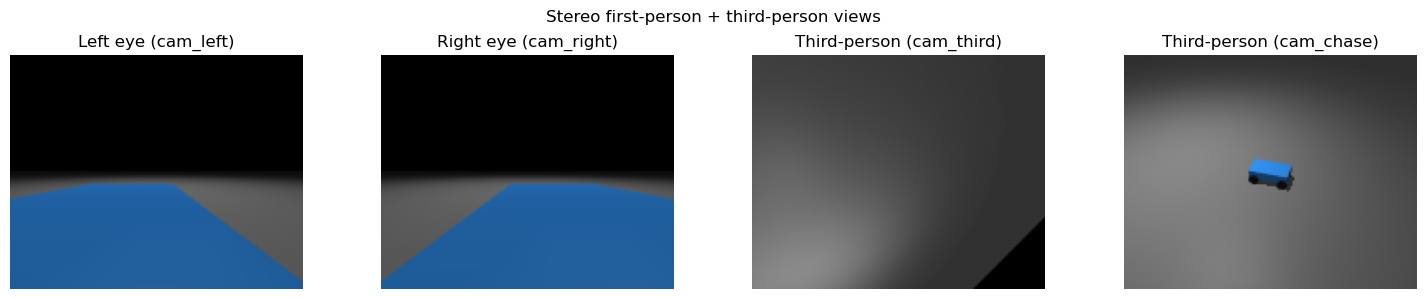

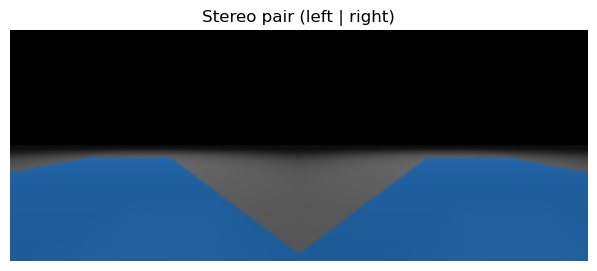

Stereo observation shape: (6, 128, 160)
Value range: 0.0 to 0.68235296


In [29]:
# ============================================================
# MuJoCo car with stereo first-person + third-person cameras
# ============================================================

import mujoco
import numpy as np
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Model definition
# ------------------------------------------------------------
CAR_XML = """
<mujoco>
  <option gravity="0 0 -9.81"/>
  <worldbody>
    <light pos="0 0 5"/>
    <geom type="plane" size="10 10 0.1" rgba="0.5 0.5 0.5 1"/>

    <!-- Third-person camera: fixed in the world, looking down at the scene -->
    <camera name="cam_third" pos="2.5 -2.5 2.5" euler="0 45 -135" fovy="60"/>
    <camera name="cam_chase"
        pos="1.5 -1.5 1.5"
        mode="targetbody"
        target="car"
        fovy="60"/>

    <!-- Car chassis -->
    <body name="car" pos="0 0 0.2">
      <freejoint name="car_free"/>
      <geom type="box" size="0.2 0.1 0.05" rgba="0.2 0.6 1 1"/>

      <!-- Stereo first-person cameras (car faces +X) -->
      <camera name="cam_left"  pos="0.2  0.06 0.08" xyaxes="0 1 0  0 0 1" fovy="70"/>
      <camera name="cam_right" pos="0.2 -0.06 0.08" xyaxes="0 1 0  0 0 1" fovy="70"/>

      <!-- Wheels -->
      <body name="wheel_fl" pos="0.15 0.1 -0.05">
        <joint name="wheel_fl_spin" type="hinge" axis="0 1 0"/>
        <geom type="cylinder" size="0.05 0.02" euler="90 0 0" rgba="0.1 0.1 0.1 1"/>
      </body>
      <body name="wheel_fr" pos="0.15 -0.1 -0.05">
        <joint name="wheel_fr_spin" type="hinge" axis="0 1 0"/>
        <geom type="cylinder" size="0.05 0.02" euler="90 0 0" rgba="0.1 0.1 0.1 1"/>
      </body>
      <body name="wheel_rl" pos="-0.15 0.1 -0.05">
        <joint name="wheel_rl_spin" type="hinge" axis="0 1 0"/>
        <geom type="cylinder" size="0.05 0.02" euler="90 0 0" rgba="0.1 0.1 0.1 1"/>
      </body>
      <body name="wheel_rr" pos="-0.15 -0.1 -0.05">
        <joint name="wheel_rr_spin" type="hinge" axis="0 1 0"/>
        <geom type="cylinder" size="0.05 0.02" euler="90 0 0" rgba="0.1 0.1 0.1 1"/>
      </body>
    </body>
  </worldbody>

  <actuator>
    <motor joint="wheel_fl_spin" name="motor_fl" ctrlrange="-1 1"/>
    <motor joint="wheel_fr_spin" name="motor_fr" ctrlrange="-1 1"/>
    <motor joint="wheel_rl_spin" name="motor_rl" ctrlrange="-1 1"/>
    <motor joint="wheel_rr_spin" name="motor_rr" ctrlrange="-1 1"/>
  </actuator>
</mujoco>
"""

# ------------------------------------------------------------
# 2. Build model + data + renderer
# ------------------------------------------------------------
model = mujoco.MjModel.from_xml_string(CAR_XML)
data = mujoco.MjData(model)
renderer = mujoco.Renderer(model, height=128, width=160)

# ------------------------------------------------------------
# 3. Helper: render all three views
# ------------------------------------------------------------
def get_all_views():
    """Return (left, right, third) images, each (128, 160, 3) uint8."""
    renderer.update_scene(data, camera="cam_left")
    left = renderer.render()

    renderer.update_scene(data, camera="cam_right")
    right = renderer.render()

    renderer.update_scene(data, camera="cam_third")
    third = renderer.render()

    renderer.update_scene(data, camera="cam_chase")
    chase = renderer.render()

    return left, right, third,chase

# ------------------------------------------------------------
# 4. Helper: render stereo observation for a neural network
# ------------------------------------------------------------
def get_stereo_obs():
    """Return a (6, 128, 160) float32 array: left + right stacked by channel."""
    left, right, _ , _ = get_all_views()
    stereo = np.concatenate([left, right], axis=2)          # (H, W, 6)
    stereo = stereo.astype(np.float32) / 255.0              # [0, 1]
    stereo = np.transpose(stereo, (2, 0, 1))                # (6, H, W)
    return stereo

# ------------------------------------------------------------
# 5. Drive the car forward a bit to see the views
# ------------------------------------------------------------
for _ in range(300):
    data.ctrl[:] = [1.0, 1.0, 1.0, 1.0]   # all wheels forward
    mujoco.mj_step(model, data)

# ------------------------------------------------------------
# 6. Render and display
# ------------------------------------------------------------
left, right, third, chase = get_all_views()

fig, axes = plt.subplots(1, 4, figsize=(15, 3))
axes[0].imshow(left)
axes[0].set_title("Left eye (cam_left)")
axes[0].axis("off")

axes[1].imshow(right)
axes[1].set_title("Right eye (cam_right)")
axes[1].axis("off")

axes[2].imshow(third)
axes[2].set_title("Third-person (cam_third)")
axes[2].axis("off")

axes[3].imshow(chase)
axes[3].set_title("Third-person (cam_chase)")
axes[3].axis("off")

plt.suptitle("Stereo first-person + third-person views")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 7. Also show the stereo pair side by side
# ------------------------------------------------------------
stereo_pair = np.concatenate([left, right], axis=1)
plt.figure(figsize=(8, 3))
plt.imshow(stereo_pair)
plt.axis("off")
plt.title("Stereo pair (left | right)")
plt.show()

# ------------------------------------------------------------
# 8. Check the observation shape for a neural network
# ------------------------------------------------------------
obs = get_stereo_obs()
print("Stereo observation shape:", obs.shape)   # (6, 128, 160)
print("Value range:", obs.min(), "to", obs.max())